# Part 4 — Stage 0: 과적합 점검

**목적** 64건만 반복 학습해서 **그대로 외우는지** 본다. 외우지 못하면 모델이 아니라 파이프라인(라벨, 마스킹, EOS, 디코딩, 점수 계산)이 잘못된 것이다.
이 단계를 통과해야 이후 Stage에서 점수가 낮을 때 "버그"와 "성능"을 구분할 수 있다.

**실행한 것**
```
python scripts/train.py --config configs/stage_0.yaml
python scripts/train.py --config configs/stage_0.yaml --name stage_0_nrng0 --set generation.no_repeat_ngram_size=0
```

**통과 기준** 같은 64건에서 ROUGE-L 90 이상. 이 점수는 학습 데이터에서 잰 **재현 점검**이지 성능이 아니다.

In [1]:
import sys, json, re, yaml
from pathlib import Path
sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"

RUNS = Path("../artifacts/runs")
r3 = sorted(RUNS.glob("*_stage_0"))[-1]
r0 = sorted(RUNS.glob("*_stage_0_nrng0"))[-1]
cfg = yaml.safe_load((r3 / "config.yaml").read_text(encoding="utf-8"))
print(r3.name, "/", r0.name)
pd.Series({**{f"train.{k}": cfg["train"][k] for k in ["learning_rate", "per_device_train_batch_size",
           "gradient_accumulation_steps", "num_train_epochs", "label_smoothing_factor", "precision"]},
           **{f"data.{k}": cfg["data"][k] for k in ["train_file", "subset_size", "eval_on"]}}).to_frame("값")

20260919_140215_stage_0 / 20260919_140535_stage_0_nrng0


,값
train.learning_rate,0.0005
train.per_device_train_batch_size,4
train.gradient_accumulation_steps,1
train.num_train_epochs,40
train.label_smoothing_factor,0.0
train.precision,bf16
data.train_file,data/subsets/stage_a.jsonl
data.subset_size,64
data.eval_on,train


## 1. 파이프라인 점검 — 라벨, EOS, 복원

In [2]:
log = (r3 / "log.txt").read_text(encoding="utf-8")
for line in log.splitlines():
    if line.startswith(("[data]", "[sanity]", "[train]")):
        print(line[:300])

[data] train 64 (data/subsets/stage_a.jsonl) / eval 64 (train 재사용)
[data] 전처리 speaker/drop, 잘린 입력 0 / 잘린 라벨 0
[sanity] 라벨이 </s> 로 끝나는 비율: 64/64
[sanity] 입력 복원: '대화 요약: P01: 카톡 사진\nP01: 한결같노\nP02: 아..\nP02: 제 유사손주입니다..\nP01: ..음.. 아이돌??\nP02: 귀여운 중국인이요\nP02: 참고로01년생이라서 유사손주임 지나가다가\nP02: 보이면 #@이름#이생각해줘\nP01: ..이거..범죄아니제?\nP02: 손주를 사랑하는것도,,조ᅵ가,,됩니까\nP02: 갠찮다 이 할미는 우리 애 잘먹고 잘 크기만을 바라니까\nP02: 천러 하고싶은거다~~해\nP02: 천러 제 손주 이름이니까 한번씩 읽고 지나가주세요</s>'
[sanity] 라벨 복원: '귀여운 중국인을 카톡 프로필 사진으로 설정하고 자신의 유사 손주라고 이야기한다.</s>'
[train] 126s, steps 640, loss 0.1228, peak VRAM 5.99GB, 시간 예산으로 중단: False


- 라벨 64건이 모두 `</s>`로 끝난다 → 모델이 "여기서 멈춘다"를 배울 수 있다
- 입력과 라벨을 다시 문자열로 복원하면 사람이 읽을 수 있는 형태다 → 토큰화가 정상이다
- 입력 중 `ㅣ`가 `ᅵ`로 보이는 것은 Part 3에서 확인한 NFKC 정규화 때문이다

## 2. loss — 외우고 있는가

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (2 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


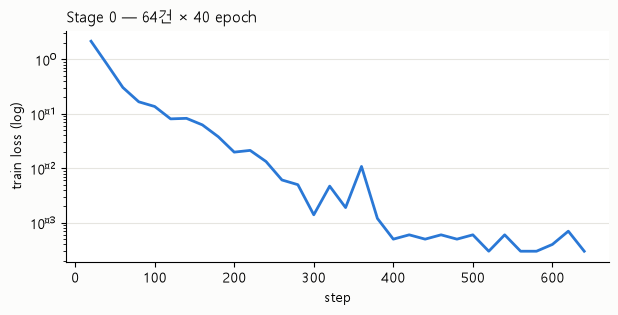

,step,epoch,loss
0,20,1.25,2.1521
3,80,5.00,0.1661
7,160,10.00,0.0626
15,320,20.00,0.0047
23,480,30.00,0.0005
31,640,40.00,0.0003


In [3]:
steps = [json.loads(m.group(2)) | {"step": int(m.group(1))}
         for m in re.finditer(r"\[step (\d+)\] (\{.*\})", log) if '"loss"' in m.group(2)]
df = pd.DataFrame(steps)
fig, ax = plt.subplots(figsize=(7, 3), facecolor="#fcfcfb")
ax.plot(df["step"], df["loss"], color="#2a78d6", linewidth=2)
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("train loss (log)")
ax.set_title("Stage 0 — 64건 × 40 epoch", loc="left", fontsize=11)
ax.grid(axis="y", color="#e6e5e0"); [ax.spines[s].set_visible(False) for s in ["top", "right"]]
plt.show()
df[["step", "epoch", "loss"]].iloc[[0, 3, 7, 15, 23, -1]]

## 3. 결과 — 통과, 그리고 디코딩 설정의 문제

In [4]:
rows = {}
for r in (r3, r0):
    m = json.loads((r / "metrics.json").read_text(encoding="utf-8"))
    rows[m["decoding"]] = {"ROUGE-L space": m["rouge"]["space"]["rougeL"], "ROUGE-L morph": m["rouge"]["morph"]["rougeL"],
                           "학습 loss": m["train_loss"], "peak VRAM GB": m["peak_vram_gb"], "학습 초": m["train_sec"]}
pd.DataFrame(rows).T

,ROUGE-L space,ROUGE-L morph,학습 loss,peak VRAM GB,학습 초
beam4/nrng3/lp1.0/max64,97.975,98.812,0.1228,5.99,126.3
beam4/nrng0/lp1.0/max64,99.623,99.635,0.1228,5.99,126.5


두 run은 **학습이 완전히 같다**(같은 시드, loss 일치). 바꾼 것은 생성할 때의 `no_repeat_ngram_size` 하나뿐이다.

`no_repeat_ngram_size=3`은 "같은 토큰 3개 묶음을 두 번 생성하지 마라"는 규칙이다. 반복 생성을 막으려고 흔히 쓰지만,
모델이 정답을 완벽히 외웠어도 **정답 안에 같은 3-gram이 두 번 있으면 두 번째를 다른 말로 바꿔야 한다.**

In [5]:
p3 = {j["id"]: j for j in map(json.loads, (r3 / "predictions.jsonl").open(encoding="utf-8"))}
p0 = {j["id"]: j for j in map(json.loads, (r0 / "predictions.jsonl").open(encoding="utf-8"))}
diff = [{"정답": p3[i]["ref"], "nrng3 출력": p3[i]["pred"], "nrng0 출력": p0[i]["pred"]}
        for i in p3 if p3[i]["rougeL_space"] < 100]
pd.set_option("display.max_colwidth", None)
pd.DataFrame(diff).head(6)

,정답,nrng3 출력,nrng0 출력
0,30살 전에는 결혼 안 할 건데 결혼 이야기가 돈다고 한다.,30살 전에는 결혼 안 할 건데 결혼이야기가 돈다고 한다.,30살 전에는 결혼 안 할 건데 결혼 이야기가 돈다고 한다.
1,엠비티아이(mbti) 해보라 해서 하니 아이에스에프피(ISFP)가 나오고 자기는 아이에스티제이(ISTJ)가 나왔다.,엠비티아이(mbti) 해보라 해서 하니 아이에스에프피(ISFP)가 나오고 자기는 아이에스티제이(IsTJ)이 나왔다.,엠비티아이(mbti) 해보라 해서 하니 아이에스에프피(ISFP)가 나오고 자기는 아이에스티제이(ISTJ)가 나왔다.
2,언니랑 아빠랑 완전 똑같이 닮았다고 하자 엄마를 닮았다고 하는 게 더 낫다고 계속 부정을 한다.,언니랑 아빠랑 완전 똑같이 닮았다고 하자 엄마를 닮아서 하는 게 더 낫다고 계속 부정을 한다.,언니랑 아빠랑 완전 똑같이 닮았다고 하자 엄마를 닮았다고 하는 게 더 낫다고 계속 부정을 한다.
3,요즘 스릴러 웹툰만 보는 중이라면서 현혹이라는 웹툰을 추천해 주는데 다른 사람은 다른 네이버 웹툰에 꽂혔다고 한다.,요즘 스릴러 웹툰만 보는 중이라면서 현혹이라는 웹툰을 추천해 주는데 다른 사람은 다른(?) 네이버 웹툰에 꽂혔다고 한다.,요즘 스릴러 웹툰만 보는 중이라면서 현혹이라는 웹툰을 추천해 주는데 다른 사람은 다른 네이버 웹툰에 꽂혔다고 한다.
4,동생은 아빠를 닮아서 뼈가 얇고 체형이 말랐으며 나는 엄마를 닮아서 동글동글하고 살집이 있다.,동생은 아빠를 닮아서 뼈가 얇고 체형이 말랐으며 나는 엄마를 닮았다고 동글동글하고 살집이 있다.,동생은 아빠를 닮아서 뼈가 얇고 체형이 말랐으며 나는 엄마를 닮아서 동글동글하고 살집이 있다.
5,한국 맞춤법이 제일 어려워서 자신이 없는데 인간미가 넘쳐서 괜찮고 구멍투성이라 스펙 하나라도 있어야 된다고 한다.,한국 맞춤법이 제일 어려워서 자신이 없는데 사람이 너무 완벽해서 스펙 하나라도 있어야 된다고 한다.,한국 맞춤법이 제일 어려워서 자신이 없는데 사람이 너무 완벽해서 스펙 하나라도 있어야 된다고 한다.


`아빠를 닮아서 … 엄마를 닮아서` → `엄마를 닮았다고`처럼, 3-gram 금지가 정답의 자연스러운 반복을 막는다.
금지를 끄면 12건 중 11건이 정답 그대로 나온다.

### 이게 일부 사례인가, 구조적인 문제인가 — 정답 쪽에서 직접 세기

모델 없이, 정답 요약문 자체에 같은 토큰 n-gram이 반복되는 비율을 센다. 이 비율만큼은 `no_repeat_ngram_size=n`으로 **정답을 원문 그대로 생성할 수 없다.**

In [6]:
from transformers import AutoTokenizer
from src.data_loader import read_jsonl
from src.evaluate import repeat_rates
tok = AutoTokenizer.from_pretrained("paust/pko-t5-base")
refs = [r["target"] for r in read_jsonl("../data/subsets/stage_b.jsonl")]
pd.Series(repeat_rates(tok, refs, ns=(2, 3, 4, 5)), name=f"정답 {len(refs):,}건 중 반복 비율 %").to_frame().T

C:\Users\KDS10\anaconda3\envs\dialogue-sum\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,n2,n3,n4,n5
"정답 20,000건 중 반복 비율 %",44.49,13.63,6.07,1.97


(stage_b 2만 건 기준. train 전체 278,292건에서는 n=3이 13.37%로 거의 같다.)

**정답의 약 13%를 원천적으로 막는 설정**이다. 한국어 요약은 조사·어미 조합(`~를 닮아서`, `~다고 한다`)이 반복되는 게 자연스럽기 때문이다.

## 결론

| 항목 | 내용 |
|---|---|
| Stage 0 | **통과.** 재현 점검 ROUGE-L 97.98 (space, beam4/nrng3) ≥ 90 |
| 확인된 것 | 데이터 로딩, 라벨 마스킹, EOS, bf16 학습, 생성, ROUGE 계산이 끝까지 정상 |
| 발견 | `no_repeat_ngram_size=3`이 정답의 13.4%를 원천적으로 막는다 |
| 남은 결정 | Stage A 전에 디코딩 기본값을 확정하고, 그 뒤로는 고정한다 (실험 로그 참고) |